In [1]:
import sys
# Remove any cached version of the module
for key in list(sys.modules.keys()):
    if 'LearnML' in key:
        del sys.modules[key]
        

In [2]:
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))

# Verify path
print("Path added:", Path.cwd().parent)
#the previous lines is necessary to ensure that the LearnML library is correctly imported and used in the notebook, allowing for testing and experimentation with the regression models and their associated functions.

from LearnML.supervised.logistic_regression import LogisticRegression
from LearnML.selection.split import train_test_split
from LearnML.learn_about.learn_about import learn_about_LogisticRegression
from LearnML.metrics.metrics import classification_report



Path added: /home/mo/Documents/LearnML_Library


Logistic Regression is a supervised learning algorithm used for binary classification. Despite its name, it does not perform regression — it predicts the probability that an input belongs to class 1, then thresholds that probability into a class label (0 or 1).

Key Concepts:
1. Sigmoid Function: Instead of a raw linear output, logistic regression passes X·w+b through sigmoid: σ(z) = 1/(1+e⁻ᶻ). This squashes any value into (0, 1), giving us a probability.
2. Loss Function: Logistic regression uses Cross-Entropy loss (not MSE). It penalizes confident wrong predictions very heavily: J = -(1/m) Σ [ y·log(ŷ) + (1-y)·log(1-ŷ) ]
3. Gradient Descent: Weights are updated the same way as linear regression — the cross-entropy gradient simplifies cleanly to dw = (1/m)·Xᵀ(ŷ−y).
4. Decision Boundary: predict() applies a threshold at 0.5 — if sigmoid output > 0.5 → class 1, else class 0.

Applications:
- Classifying emails as spam or not spam.
- Predicting whether a tumor is malignant or benign.
- E

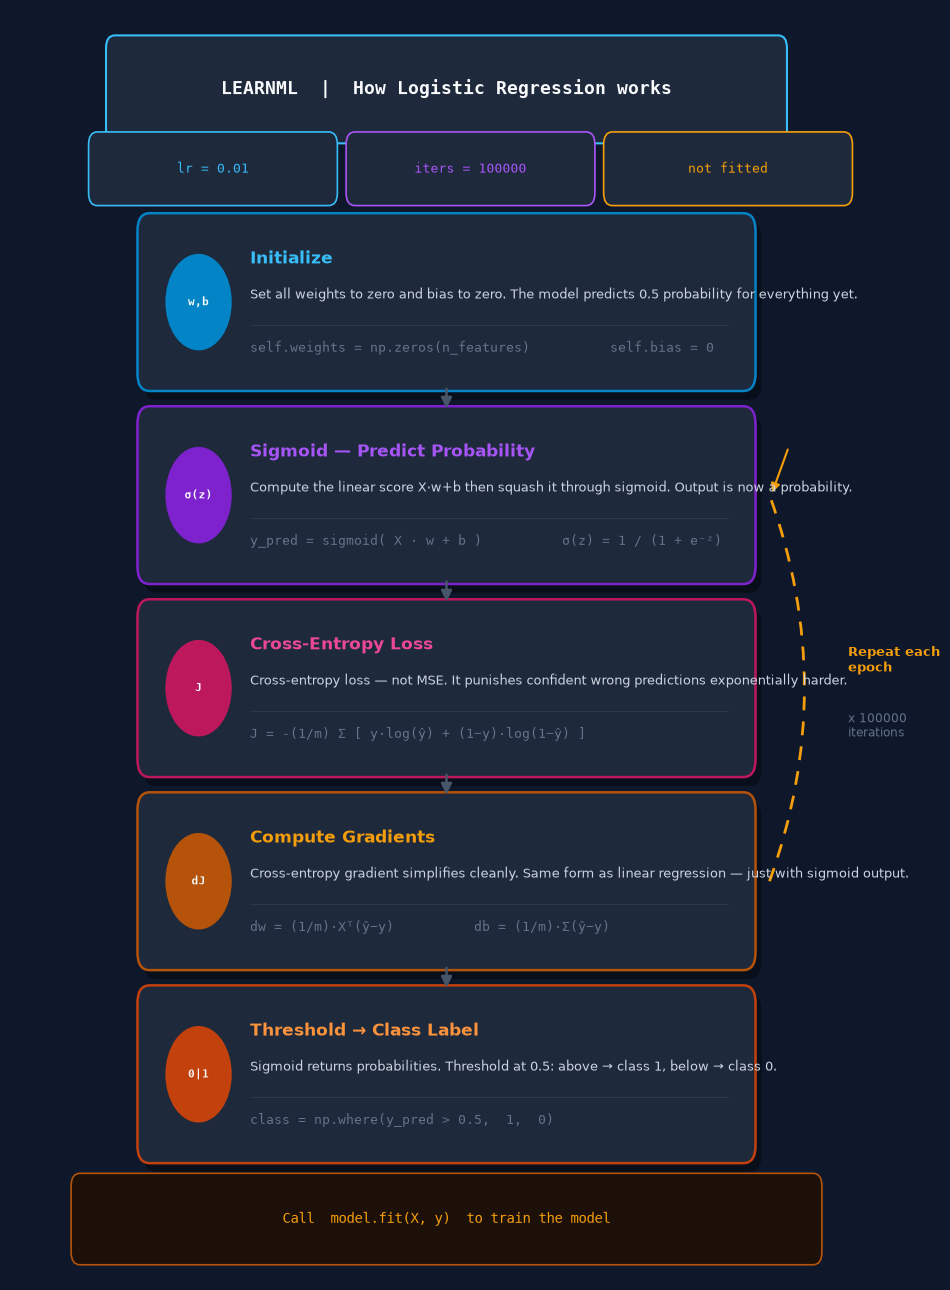

In [3]:
learn_about_LogisticRegression()

In [51]:
from sklearn.datasets import make_classification


from sklearn.datasets import make_classification

# Generate 2000 samples with single cluster per class and strong separation
X, y = make_classification(
    n_samples=2000,         # Total number of rows/samples
    n_features=10,          # Total number of input features
    n_informative=8,        # Informative features (8 out of 10)
    n_redundant=1,          # Redundant features (linear combinations)
    # Remaining 1 feature is pure random noise
    n_classes=2,            # Number of target categories
    n_clusters_per_class=1, # One unimodal cluster per class
    class_sep=1.00,         # Wide separation between class clusters
    weights=[0.55, 0.45],   # Class balance (55%, 45%)
    flip_y=0.02,            # 2% random label noise (0.0 for clean labels)
    random_state=42         # Seed for reproducibility
)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)



Text(0.5, 1.0, 'Training Data Distribution')

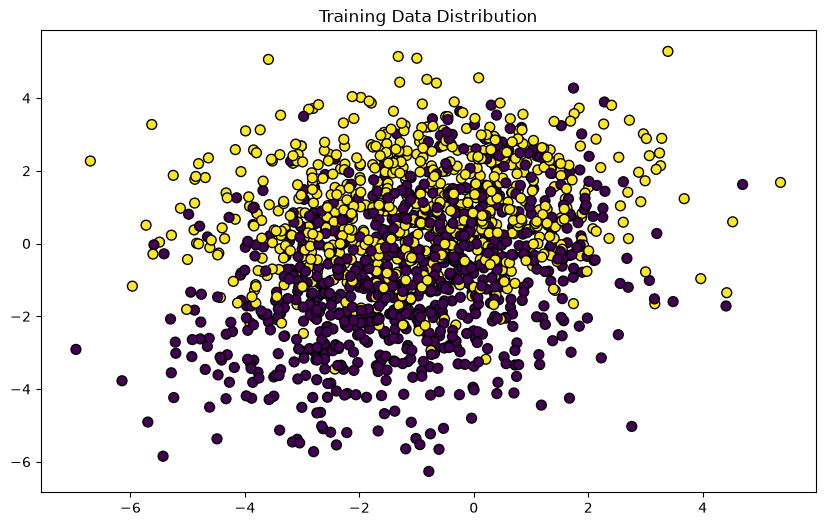

In [52]:
#visualize the data distribution
import matplotlib.pyplot as plt
plt.figure(figsize=(10, 6))
plt.scatter(X_train[:, 0], X_train[:, 1], c=y_train, cmap='viridis', edgecolor='k', s=50)
plt.title('Training Data Distribution')     

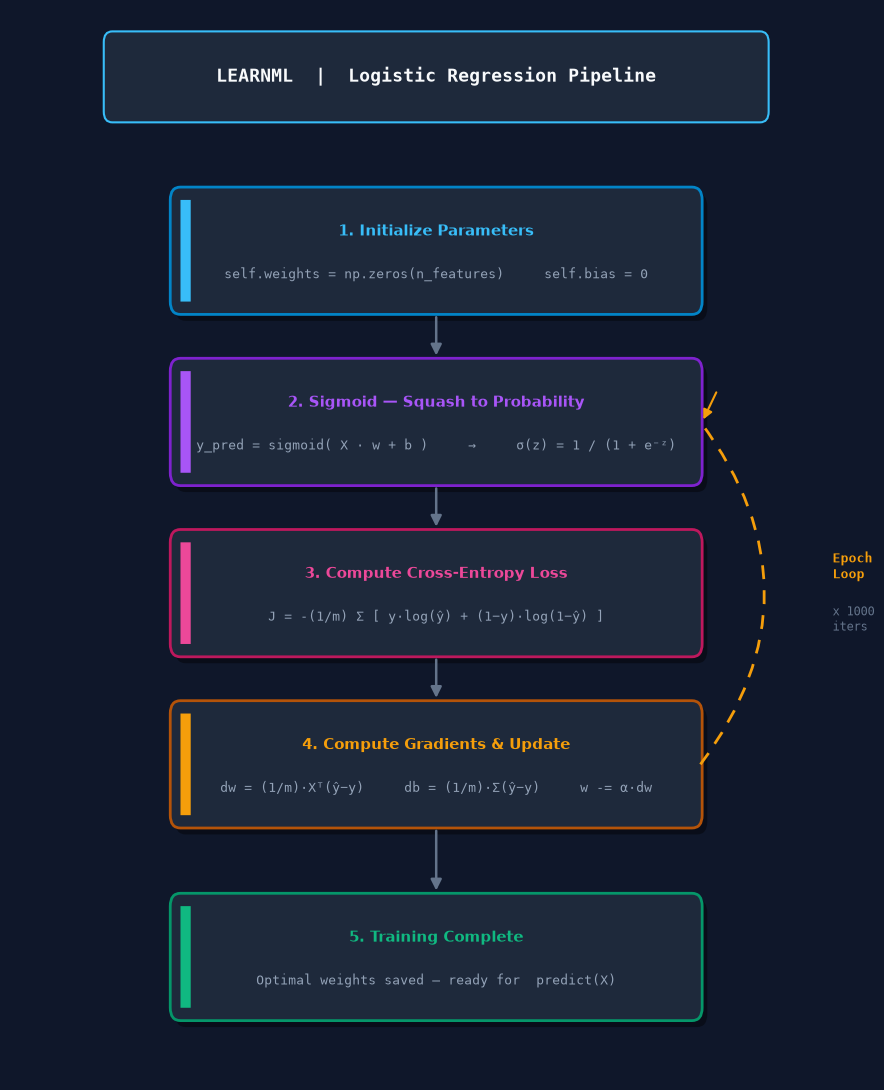

In [53]:
log_reg_model=LogisticRegression(learning_rate=0.01, n_iters=1000)
log_reg_model.fit(X_train, y_train)

In [54]:
predictions= log_reg_model.predict(X_test)
predictions

array([0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 1, 1, 1,
       1, 0, 1, 1, 0, 1, 0, 0, 1, 1, 0, 1, 1, 0, 1, 1, 1, 1, 0, 0, 1, 1,
       0, 1, 0, 1, 1, 0, 0, 0, 0, 0, 1, 1, 1, 1, 0, 1, 1, 0, 1, 0, 0, 1,
       1, 1, 0, 0, 1, 0, 0, 0, 1, 1, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 0, 1,
       0, 0, 1, 1, 0, 1, 0, 1, 1, 0, 0, 0, 0, 1, 1, 0, 0, 1, 1, 1, 1, 1,
       1, 1, 1, 0, 0, 0, 0, 0, 0, 1, 1, 1, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0,
       0, 1, 0, 0, 1, 0, 0, 1, 0, 1, 0, 0, 0, 0, 1, 0, 1, 0, 0, 0, 1, 0,
       0, 0, 1, 1, 0, 0, 0, 1, 1, 0, 0, 1, 1, 1, 0, 1, 0, 0, 0, 0, 0, 0,
       1, 0, 1, 1, 0, 1, 1, 0, 1, 1, 1, 0, 0, 1, 1, 1, 0, 1, 0, 1, 1, 1,
       0, 1, 0, 0, 1, 0, 0, 1, 1, 1, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0,
       0, 1, 0, 1, 0, 1, 0, 0, 0, 1, 0, 0, 0, 0, 1, 1, 1, 0, 1, 0, 0, 0,
       0, 0, 1, 1, 1, 1, 0, 0, 0, 0, 0, 1, 1, 0, 1, 0, 1, 0, 1, 0, 0, 1,
       0, 0, 1, 0, 0, 0, 1, 0, 1, 1, 1, 1, 0, 1, 1, 0, 1, 1, 1, 0, 1, 0,
       1, 0, 1, 0, 1, 1, 0, 0, 0, 0, 1, 0, 1, 1, 1,

In [55]:
classification_report(y_test,predictions)

Accuracy: 0.9625
Precision: 0.9662921348314607
Recall: 0.9502762430939227
F1 Score: 0.9582172701949861
